# PEnKF

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from penkf import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights, esses, ensembles = filter(stations, z, n=100, m=10, T=10)

In [5]:
theta[10]

tensor(2.4623)

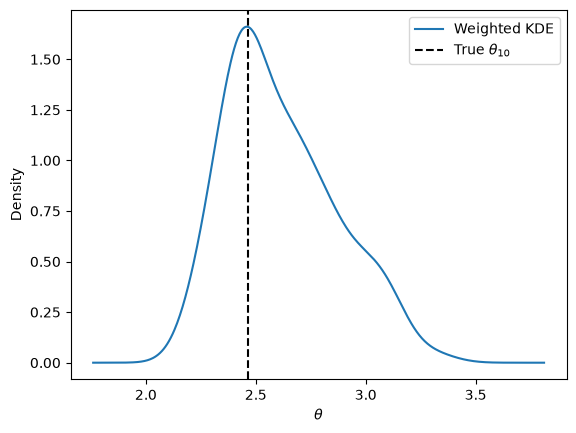

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

t = 10
thetas = torch.stack([torch.as_tensor(p) for p in particles]).numpy()
weights = log_weights.exp().numpy()
true_theta = theta[t].item()
kde = gaussian_kde(thetas, weights=weights)
grid = np.linspace(min(thetas.min(), true_theta) - 0.5,
                   max(thetas.max(), true_theta) + 0.5, 500)
plt.plot(grid, kde(grid), label="Weighted KDE")
plt.axvline(true_theta, color="k", linestyle="--", label=rf"True $\theta_{{{t}}}$")
plt.xlabel(r"$\theta$")
plt.ylabel("Density")
plt.legend()
plt.show()

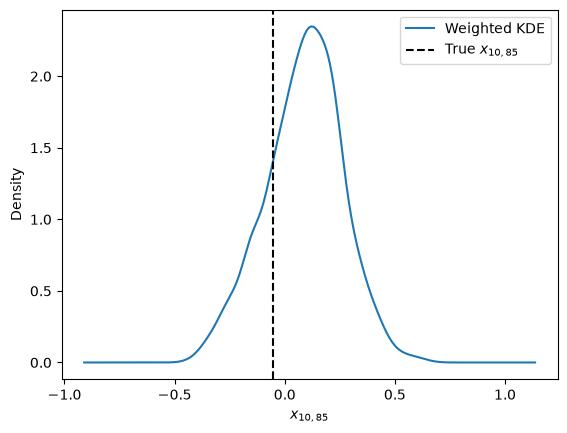

In [7]:
# Posterior samples of x are all ensemble members, each carrying its
# particle's weight divided by the ensemble size
X = torch.stack([torch.stack(e) for e in ensembles]).numpy() # (n, m, grid)
x_weights = np.repeat(weights/X.shape[1], X.shape[1])

def plot_weighted_kde(samples, true_value, label):
    kde = gaussian_kde(samples, weights=x_weights)
    grid = np.linspace(min(samples.min(), true_value) - 0.5,
                       max(samples.max(), true_value) + 0.5, 500)
    plt.plot(grid, kde(grid), label="Weighted KDE")
    plt.axvline(true_value, color="k", linestyle="--", label=f"True {label}")
    plt.xlabel(label)
    plt.ylabel("Density")
    plt.legend()
    plt.show()

rng = np.random.default_rng(0)
k = rng.integers(X.shape[2])
plot_weighted_kde(X[:, :, k].ravel(), x[t, k].item(), rf"$x_{{{t},{k}}}$")

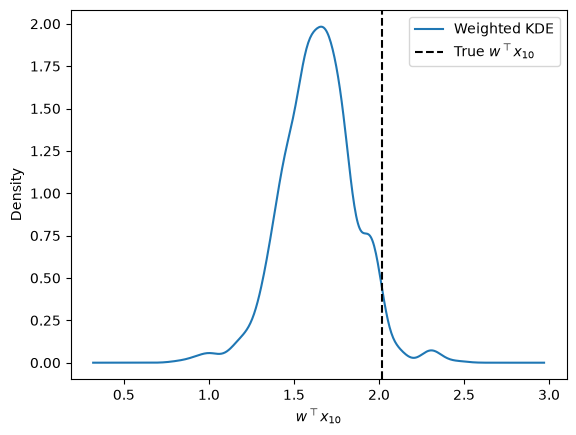

In [8]:
w = rng.standard_normal(X.shape[2])
w /= np.linalg.norm(w)
plot_weighted_kde((X @ w).ravel(), float(x[t].numpy() @ w), rf"$w^\top x_{{{t}}}$")

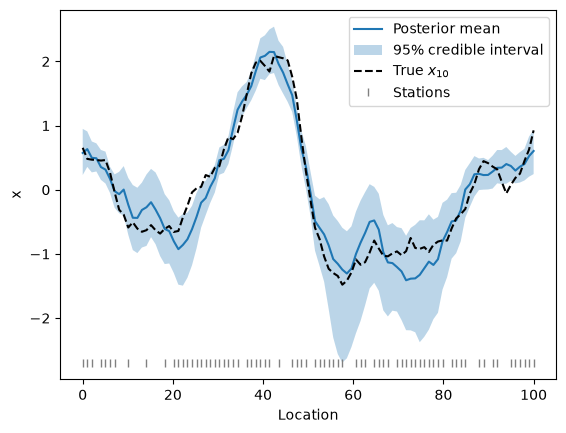

In [9]:
def weighted_quantiles(samples, weights, qs):
    """ Weighted quantiles of each column of samples (N, g), shape (len(qs), g) """
    order = np.argsort(samples, axis=0)
    s = np.take_along_axis(samples, order, axis=0)
    w = weights[order]
    cdf = np.cumsum(w, axis=0) - w/2 # midpoint cdf, so a single sample is not a step
    return np.stack([np.interp(qs, cdf[:, j], s[:, j]) for j in range(s.shape[1])], axis=1)

samples = X.reshape(-1, X.shape[2])
location = np.linspace(0, 100, X.shape[2]) # grid used by draw_prior_state
post_mean = x_weights @ samples
lower, upper = weighted_quantiles(samples, x_weights, [0.025, 0.975])

plt.plot(location, post_mean, label="Posterior mean")
plt.fill_between(location, lower, upper, alpha=0.3, label="95% credible interval")
plt.plot(location, x[t].numpy(), "k--", label=rf"True $x_{{{t}}}$")
plt.plot(location[stations], np.full(len(stations), lower.min()), "|", color="gray",
         label="Stations")
plt.xlabel("Location")
plt.ylabel("x")
plt.legend()
plt.show()

We have relatively high confidence in regions where there is a lot of rainfall.
This makes sense; 

In [10]:
esses

[tensor(1.8613),
 tensor(7.1633),
 tensor(13.5801),
 tensor(2.8151),
 tensor(2.0507),
 tensor(13.3006),
 tensor(22.9516),
 tensor(7.9385),
 tensor(3.2843),
 tensor(15.2655)]